# Straight tube: the system and its independent references

A passage can remain open after its straight axis becomes blocked. This finite
atomic tube lets us distinguish **space for a probe**, **a continuous route** and
**two physical boundary openings** before asking DFND what it finds.

Start with this notebook, then open [DFND observations](dfnd.ipynb).
Each runs independently from its own case directory. Run All replays retained
reference certificates; it does not import TopoMT, execute a provider, submit
coordinates to a server or overwrite evidence. Obtain the complete download
from the [case page](index.md), with the helper modules and source environment.

## A finite wall made of actual atomic balls

We reuse the catalog's `tube_channel_clean`: nine rings of nine argon balls,
nominal radius 3.5 Å, length 20 Å, ring spacing 2.5 Å, atom radius 1.88 Å,
Gaussian jitter 0.1 Å and seed 0. The **81 full-precision centers and radii** in
`input.json` define the model. The rounded PDB supplies topology only.
Source atom IDs are 0–80 and survive public receiving.

This is an isolated, nonperiodic system. Our finite study carrier is the convex
hull of the atomic centers. A sampled wall is not automatically an ideal solid
cylinder: its coverage and openings must be checked on these balls.

In [1]:
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt
import pyunitwizard as puw
from html import escape
from IPython.display import HTML, display
from study import read, quantity, references

CASE = Path.cwd()
ARTIFACTS = CASE / 'artifacts/cylinder_tube_v1'
fixture = read(ARTIFACTS / 'input.json')
coords = np.asarray(puw.get_value(quantity(fixture['coordinates'], 'coordinates'), to_unit='angstroms'))
radii = np.asarray(puw.get_value(quantity(fixture['atom_radii'], 'atom_radii'), to_unit='angstroms'))
certificate = read(ARTIFACTS / 'reference_v2_certificate.json')
path = np.asarray(certificate['path_candidate']['points_angstroms'])
independent = references(CASE)
reference = independent['passage']

def table(headers, rows):
    heading = ''.join('<th>' + escape(str(value)) + '</th>' for value in headers)
    body = ''.join('<tr>' + ''.join('<td>' + escape(str(value)) + '</td>' for value in row) + '</tr>' for row in rows)
    display(HTML('<div style="overflow-x:auto"><table class="table"><thead><tr>' + heading +
                 '</tr></thead><tbody>' + body + '</tbody></table></div>'))

assert 'topomt' not in sys.modules
assert coords.shape == (81, 3) and radii.shape == (81,)
assert fixture['source_atom_indices'] == list(range(81))
print(f'{len(coords)} balls; radius {radii[0]:.2f} Å; input SHA-256 {reference["input_sha256"]}')

81 balls; radius 1.88 Å; input SHA-256 2c389178d86bc2eb3cbbfd97e12aa14d70a71acb8759c1cb3061c2ef1a67a4b2


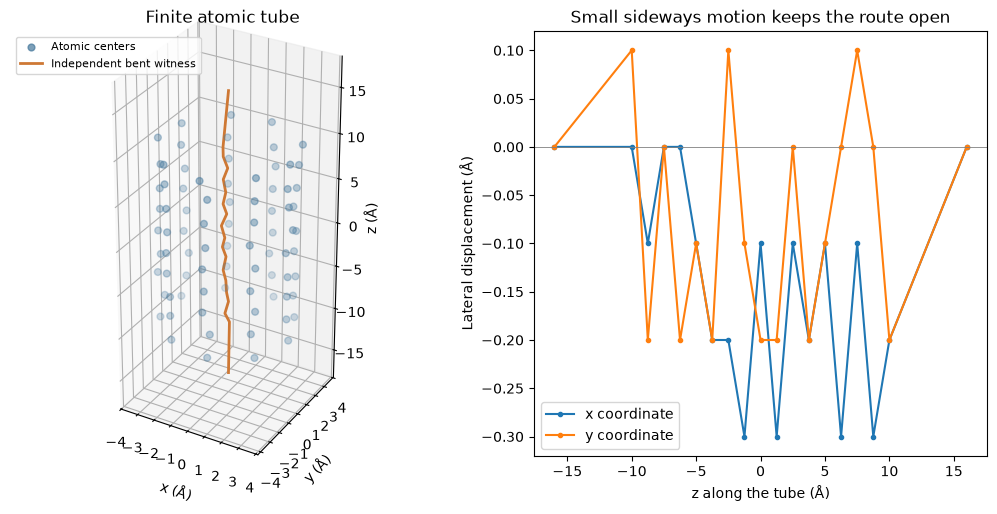

In [2]:
fig = plt.figure(figsize=(10, 5), layout='constrained')
ax = fig.add_subplot(121, projection='3d')
ax.scatter(*coords.T, s=24, color='#46789c', alpha=.7, label='Atomic centers')
ax.plot(*path.T, color='#ce7834', lw=2, label='Independent bent witness')
ax.set(xlabel='x (Å)', ylabel='y (Å)', zlabel='z (Å)', title='Finite atomic tube')
ax.set_box_aspect((1, 1, 2.3))
ax.legend(fontsize=8, loc='upper left')
side = fig.add_subplot(122)
side.plot(path[:, 2], path[:, 0], 'o-', ms=3, label='x coordinate')
side.plot(path[:, 2], path[:, 1], 'o-', ms=3, label='y coordinate')
side.axhline(0, color='grey', lw=.6)
side.set(xlabel='z along the tube (Å)', ylabel='Lateral displacement (Å)',
         title='Small sideways motion keeps the route open')
side.legend()
plt.show()

The left panel shows **centers**, with marker sizes chosen for visibility rather
than atomic radii. The right panel expands the lateral motion on its own labeled
axis. Neither drawing supplies the geometric proof.

## Three probes, three questions

Clearance at a point is the minimum distance to **all 81 centers**, minus the
corresponding atomic radius. Our independent designated-axis clearance is
**1.395213786 Å**. At 1.2 Å the axis is clear; at 1.4 Å it is blocked.
Blocking one line does not prove that the passage is closed.

The first frozen reference search required the path to visit the origin. That
point itself has clearance 1.395730210 Å, so this requirement cannot certify the
1.4 Å route. Before any new DFND receiving, we retained that attempt and froze
a second protocol that removes only this anchoring constraint. A bounded layered
grid then supplied the bent witness plotted above. This is retrospective
development on an existing catalog input, not a blind evaluation panel.

In [3]:
table(['Probe (Å)', 'Fixed axis', 'Independent route', 'Finite hull'], [
    [row['probe_angstroms'], row['fixed_axis'], row['end_to_end_path'], row['finite_hull']]
    for row in reference['controls']])
clearance = reference['path_minimum_clearance_angstroms']
assert clearance > 1.4 + 1e-6
axis = reference['model_reference']['axis_clearance_angstroms']
offset = 1e-4
assert axis - (axis - offset) > 1e-6
assert axis - (axis + offset) < -1e-6
print(f'Whole bent polyline minimum clearance: {clearance:.12f} Å')
print(f'Its margin at 1.4 Å: {clearance - 1.4:.12f} Å')
print('Axis-only bracket:', axis - offset, axis + offset, 'Å; equality remains marginal.')

Probe (Å),Fixed axis,Independent route,Finite hull
1.2,clear,certified,not_established
1.4,blocked,certified,not_established
2.5,blocked,not_established,strictly_covered


Whole bent polyline minimum clearance: 1.440735020678 Å
Its margin at 1.4 Å: 0.040735020678 Å
Axis-only bracket: 1.3951137863301655 1.3953137863301655 Å; equality remains marginal.


### Why the route is a certificate

For each segment and atom, the checker projects that atom onto the complete
closed segment, clamps the projection to its endpoints and evaluates the exact
distance there. The minimum across all segments and balls is **1.440735021 Å**.
The positive 1.4 Å margin is **0.040735021 Å**, well above the declared 1e-6 Å
decision margin. Checking only the plotted stations would be insufficient.
Both endpoints lie beyond every atomic center along z; on their outward axial
rays every atomic distance increases. The verified path therefore connects the
two ends to the unbounded exterior.

The search is finite (1,379 stations, 33,102 candidate edges); the **independent
complete-segment replay**, rather than an optimality claim for that search,
establishes this one route. The best possible global bottleneck is unavailable.

## Are there exactly two physical openings?

A route between the ends does not exclude a side-wall leak. We separately
replay a complete hull inventory: **46 triangles**, with **32 covered lateral
triangles** and **14 end triangles**. Positive convex-ball subdivision
certificates cover every lateral triangle. Complete convex-intersection
certificates establish the free subsets of the end triangles. Analytic seam
intervals and covered hull vertices complete the connectivity check.

In [4]:
table(['Probe (Å)', 'Hull faces', 'Covered wall faces', 'Free end faces', 'Free seams', 'Physical patches'], [
    [probe, result['complete_hull_faces'], result['covered_wall_faces'],
     result['free_end_faces'], result['free_seams'], result['opening_component_count']]
    for probe, result in independent['boundary'].items()])
for result in independent['boundary'].values():
    assert result['opening_component_count'] == 2
    assert result['covered_wall_faces'] == 32 and result['free_seams'] == 0
    assert sorted(result['component_end_labels']) == ['negative_z', 'positive_z']

Probe (Å),Hull faces,Covered wall faces,Free end faces,Free seams,Physical patches
1.2,46,32,2,0,2
1.4,46,32,2,0,2


Thus each smaller probe has **two disconnected strict-free hull patches**, one
at each end, and the verified passage joins the ends. No aperture area or
biological mouth annotation follows from this patch count. The initial generic
boundary discovery exhausted its 4,000-solver-call budget; that failed attempt
is retained. The later wall-first certificates settle the count without
accepting a partial result.

## A decisive negative control: 2.5 Å

Hull convexity bounds radial distance and z. For any hull point, choose the
nearest nominal ring and angular column. Maximizing the resulting squared
radial-distance expression over its finite interval occurs at an endpoint;
add the measured maximum atom displacement by the triangle inequality.
This gives the sufficient **actual-atom distance bound 4.083579632 Å** over the
whole finite hull. At 2.5 Å the expanded ball radius is **4.38 Å**: the entire
carrier is strictly covered with a **0.296420368 Å** margin.

This proves no free probe center inside this finite carrier, including its
boundary. It does not remove the unbounded exterior or prove that two points
cannot connect by going around the outside of the tube. A failed witness search
alone would not establish this negative result.

In [5]:
model = reference['model_reference']
assert model['exclusion']['2.5']['strictly_covered']
print('Finite-hull cover bound:', model['finite_hull_cover_distance_bound_angstroms'], 'Å')
print('Exclusion margin:', model['exclusion']['2.5']['coverage_margin_angstroms'], 'Å')
assert 'topomt' not in sys.modules
print('Independent replay complete; TopoMT has not been imported.')

Finite-hull cover bound: 4.083579632239034 Å
Exclusion margin: 0.29642036776096603 Å
Independent replay complete; TopoMT has not been imported.


## What we will ask DFND

At 1.2 and 1.4 Å, inspect native wet/dry banks, reported regions, exterior links,
physical patch counts and their supports. A graph path is a candidate: check its
complete segments against all balls. At 2.5 Å, compare local/public candidates
with the independently empty finite carrier before interpreting their names.

Continue with [DFND observations](dfnd.ipynb). The [artifact guide](artifacts/cylinder_tube_v1/README.md)
links the frozen protocols, independent checkers, retained attempts, source
identities and receipts. Exact free volume, aperture area, optimal path and
original-provider comparisons are unavailable at this stage.